# Hand2Panda — Clean Data & Motion-Prior Pipeline

**Purpose:** process the 20 personally recorded phone videos, extract object trajectories, normalise the paths, and build a simple human-motion prior for later LIBERO/Panda integration.

## Current project status

- A SmolVLA/LIBERO smoke test ran in the earlier notebook; it is a pretrained reference, not yet trained on the personal videos.
- 20 phone videos have been captured: 16 training demonstrations (`L1`–`L4`) and 4 held-out demonstrations (`L5`–`L6`).
- The previous sweep extracted all 20 trajectories. 13 passed the extractor's automated checks; 7 had endpoint-distance warnings. The user reports that the object physically landed on the target in all recordings, so these warnings are treated as measurement/calibration warnings, not automatic proof of failed demonstrations.
- Normalised paths were generated for all 20 videos, and a global median motion prior was calculated from the 16 training paths.

## Important caveats

- Make sure `VIDEO_SOURCE_DIR` points to the **orientation-corrected** videos. A `/content/...` folder is temporary; for a fresh runtime, place the corrected videos in Drive and point the variable to that folder.
- The current camera-marker geometry and some estimated lift heights are imperfect. This pipeline preserves the measurements and reports warnings; it does not make the measurements accurate by forcing QC to pass.
- The normalised trajectories describe 2D path shape. Do not use the extracted height curves as robot lift commands without further validation; use safe geometric lift/lower motions during the first simulation integration.
- The robot has **not yet** been controlled by the human-derived trajectory. That is the next development milestone.

Run the cells **in order** from top to bottom. Change the camera height and source folder in the configuration cell if required.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import shutil
import json
import subprocess
import sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Shared ArUco detector used by the preflight and QC cells.
if not hasattr(cv2, 'aruco'):
    raise RuntimeError('cv2.aruco is unavailable. Install opencv-contrib-python-headless, restart the runtime, and rerun from the top.')
dictionary = cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_4X4_50)
params = cv2.aruco.DetectorParameters()
detector = cv2.aruco.ArucoDetector(dictionary, params)

# ---- Paths ----
DRIVE_VIDEO_DIR = Path('/content/drive/MyDrive/Humanoid/dataset')
LOCAL_CORRECTED_DIR = Path('/content/raw')

# Prefer the corrected videos if they are present in the current runtime.
# Otherwise use the Drive folder above; make sure it contains corrected clips.
VIDEO_SOURCE_DIR = LOCAL_CORRECTED_DIR if LOCAL_CORRECTED_DIR.exists() else DRIVE_VIDEO_DIR
RAW_DIR = Path('/content/raw')
SCRIPT_PATH = Path('/content/extract_tracks.py')
TRACKS_DIR = Path('/content/tracks_quality_sweep')
NORMALIZED_DIR = Path('/content/normalized_dataset')

# ---- Physical calibration ----
TABLE_W_M = 0.70
TABLE_H_M = 0.36
CAM_HEIGHT_M = 0.65  # Set to the measured/corrected lens-to-table height in metres.

VIDEO_EXTENSIONS = {'.mp4', '.mov', '.m4v', '.avi'}
EXPECTED_NAMES = (
    [f'L{i}_{j:02d}' for i in range(1, 5) for j in range(1, 5)]
    + [f'L{i}_{j:02d}' for i in (5, 6) for j in range(1, 3)]
)
TRAIN_NAMES = [f'L{i}_{j:02d}' for i in range(1, 5) for j in range(1, 5)]
TEST_NAMES = [f'L{i}_{j:02d}' for i in (5, 6) for j in range(1, 3)]

print('Video source:', VIDEO_SOURCE_DIR)
print('Camera height (m):', CAM_HEIGHT_M)
print('Table dimensions (m):', TABLE_W_M, 'x', TABLE_H_M)

if VIDEO_SOURCE_DIR == DRIVE_VIDEO_DIR:
    print('NOTE: Confirm the Drive folder contains your corrected/orientation-fixed videos.')

Mounted at /content/drive
Video source: /content/drive/MyDrive/Humanoid/dataset
Camera height (m): 0.65
Table dimensions (m): 0.7 x 0.36
NOTE: Confirm the Drive folder contains your corrected/orientation-fixed videos.


## 1. Validate and stage the 20 videos

The expected names are `L1_01` through `L4_04`, plus `L5_01`, `L5_02`, `L6_01`, and `L6_02`. The split is fixed: L1–L4 are training; L5–L6 are held out.

In [ ]:
assert VIDEO_SOURCE_DIR.exists(), f'Video source folder not found: {VIDEO_SOURCE_DIR}'

video_candidates = [
    p for p in VIDEO_SOURCE_DIR.rglob('*')
    if p.is_file() and p.suffix.lower() in VIDEO_EXTENSIONS
]
by_stem = {}
for p in video_candidates:
    by_stem.setdefault(p.stem, []).append(p)

missing = [name for name in EXPECTED_NAMES if name not in by_stem]
duplicates = {name: paths for name, paths in by_stem.items()
              if name in EXPECTED_NAMES and len(paths) > 1}

print('Expected videos:', len(EXPECTED_NAMES))
print('Video files found:', len(video_candidates))
print('Missing expected videos:', missing)
print('Duplicate expected filenames:', list(duplicates))

if missing or duplicates:
    raise RuntimeError(
        'Resolve missing/duplicate filenames before processing. '
        'If corrected videos are in another folder, update VIDEO_SOURCE_DIR.'
    )

RAW_DIR.mkdir(parents=True, exist_ok=True)
# Clear old video copies so stale files from a previous run are not mixed in.
for old in RAW_DIR.iterdir():
    if old.is_file() and old.suffix.lower() in VIDEO_EXTENSIONS:
        old.unlink()

for name in EXPECTED_NAMES:
    shutil.copy2(by_stem[name][0], RAW_DIR / by_stem[name][0].name)

print(f'Copied {len(EXPECTED_NAMES)} videos to {RAW_DIR}')

Expected videos: 20
Video files found: 20
Missing expected videos: []
Duplicate expected filenames: []
Copied 20 videos to /content/raw


## 2. Write the trajectory extractor

This is the original four-corner extractor. It requires the four table markers to be visible together in at least 10 frames. The batch QC cell also records how many frames satisfy that condition.

In [ ]:
%%writefile /content/extract_tracks.py
import argparse
import json
import os

import cv2
import numpy as np
from scipy.signal import savgol_filter

CORNER_IDS = (0, 1, 2, 3)
OBJ_ID, PLATE_ID = 10, 11
MOVE_THRESH = 0.015          # m, motion onset / offset threshold
MAX_GAP_S = 0.4              # longest gap we are willing to interpolate


def detect_all(video_path):
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise FileNotFoundError(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    W = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    H = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    params = cv2.aruco.DetectorParameters()
    params.cornerRefinementMethod = cv2.aruco.CORNER_REFINE_SUBPIX
    det = cv2.aruco.ArucoDetector(cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_4X4_50), params)
    frames = []                                   # list of {id: (4,2) corners}
    first_frame = None
    while True:
        ok, img = cap.read()
        if not ok:
            break
        if first_frame is None:
            first_frame = img.copy()
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        corners, ids, _ = det.detectMarkers(gray)
        d = {}
        if ids is not None:
            for c, i in zip(corners, ids.flatten()):
                d[int(i)] = c.reshape(4, 2).astype(np.float64)
        frames.append(d)
    cap.release()
    return frames, fps, (W, H), first_frame


def side_px(c):
    return float(np.mean([np.linalg.norm(c[k] - c[(k + 1) % 4]) for k in range(4)]))


def centre(c):
    return c.mean(axis=0)


def calibrate_table(frames, table_w, table_h, corner_mm):
    """Homography image->table (metres) plus nadir and table-marker pixel size."""
    table_xy = np.array([[0, 0], [table_w, 0], [table_w, table_h], [0, table_h]], np.float64)
    full = [f for f in frames if all(i in f for i in CORNER_IDS)]
    if len(full) < 10:
        raise RuntimeError(f"corner markers 0-3 all visible in only {len(full)} frames; "
                           "check that all four are in view and not occluded at the start")
    full = full[: max(10, min(len(full), 90))]
    ctr = np.array([[np.median([centre(f[i])[k] for f in full]) for k in (0, 1)] for i in CORNER_IDS])
    s_tab = float(np.median([side_px(f[i]) for f in full for i in CORNER_IDS]))
    Hm, _ = cv2.findHomography(ctr, table_xy)
    return Hm, s_tab, ctr


def to_table(Hm, pts):
    pts = np.asarray(pts, np.float64).reshape(-1, 1, 2)
    return cv2.perspectiveTransform(pts, Hm).reshape(-1, 2)


def marker_series(frames, mid, Hm, nadir, s_tab, size_ratio, z0):
    """Per-frame (x, y, h) of one marker in the table frame; NaN where not detected.
    size_ratio = true_marker_size / true_table_marker_size."""
    T = len(frames)
    out = np.full((T, 3), np.nan)
    for t, f in enumerate(frames):
        if mid not in f:
            continue
        p_app = to_table(Hm, centre(f[mid]))[0]
        r = size_ratio * s_tab / side_px(f[mid])        # Z / Z0
        out[t, :2] = nadir + (p_app - nadir) * r
        out[t, 2] = z0 * (1.0 - r)
    return out


def fill_gaps(x, fps):
    """Linearly interpolate NaN gaps; return (filled, longest_gap_seconds, detection_rate)."""
    x = x.copy()
    bad = np.isnan(x[:, 0])
    if bad.all():
        raise RuntimeError("marker never detected")
    idx = np.arange(len(x))
    longest, run = 0, 0
    for b in bad:
        run = run + 1 if b else 0
        longest = max(longest, run)
    for k in range(x.shape[1]):
        x[bad, k] = np.interp(idx[bad], idx[~bad], x[~bad, k])
    return x, longest / fps, 1.0 - bad.mean()


def smooth(x, fps):
    win = int(round(0.2 * fps)) | 1                      # ~0.2 s, odd
    win = max(win, 5)
    if len(x) <= win:
        return x
    return savgol_filter(x, win, 2, axis=0)


def segment(xyz, fps):
    """Return (grasp_idx, release_idx, start_xyz, end_xyz) from the object's own motion."""
    n0 = max(3, int(0.5 * fps))
    start = np.median(xyz[:n0], axis=0)
    end = np.median(xyz[-n0:], axis=0)
    moving_from_start = np.linalg.norm(xyz - start, axis=1) > MOVE_THRESH
    moving_from_end = np.linalg.norm(xyz - end, axis=1) > MOVE_THRESH
    if not moving_from_start.any():
        raise RuntimeError("object never moved")
    g = int(np.argmax(moving_from_start))
    r = int(len(xyz) - 1 - np.argmax(moving_from_end[::-1]))
    if r <= g + 3:
        raise RuntimeError(f"degenerate transit window ({g}, {r})")
    return g, r, start, end


def extract(video, table_w=0.70, table_h=0.36, cam_height=0.65, corner_mm=60, obj_mm=40,
            plate_mm=40, layout="", debug_png=None):
    frames, fps, (W, H), first = detect_all(video)
    Hm, s_tab, _ = calibrate_table(frames, table_w, table_h, corner_mm)
    nadir = to_table(Hm, [[W / 2, H / 2]])[0]
    obj_raw = marker_series(frames, OBJ_ID, Hm, nadir, s_tab, obj_mm / corner_mm, cam_height)
    plate_raw = marker_series(frames, PLATE_ID, Hm, nadir, s_tab, plate_mm / corner_mm, cam_height)
    obj, longest_gap, det_rate = fill_gaps(obj_raw, fps)
    obj = smooth(obj, fps)
    g, r, start, end = segment(obj, fps)
    h_rest = float(np.median(obj[: max(3, int(0.5 * fps)), 2]))
    xyz = obj.copy()
    xyz[:, 2] -= h_rest                                   # height above the object's resting height
    plate_ok = ~np.isnan(plate_raw[:, 0])
    plate_xy = np.median(plate_raw[plate_ok, :2], axis=0) if plate_ok.any() else np.full(2, np.nan)

    qc = {
        "video": os.path.basename(video), "layout": layout, "fps": fps, "n_frames": len(frames),
        "obj_detect_rate": round(det_rate, 3), "longest_gap_s": round(longest_gap, 3),
        "grasp_idx": g, "release_idx": r, "transit_s": round((r - g) / fps, 3),
        "rest_height_est_m": round(h_rest, 4),
        "max_lift_m": round(float(xyz[g:r + 1, 2].max()), 4),
        "start_to_end_m": round(float(np.linalg.norm(end[:2] - start[:2])), 4),
        "end_to_plate_marker_m": round(float(np.linalg.norm(end[:2] - plate_xy)), 4) if plate_ok.any() else None,
    }
    warnings = []
    if longest_gap > MAX_GAP_S:
        warnings.append(f"longest detection gap {longest_gap:.2f}s > {MAX_GAP_S}s: path may be unreliable")
    if det_rate < 0.7:
        warnings.append(f"object marker detected in only {det_rate:.0%} of frames")
    if qc["end_to_plate_marker_m"] is not None and qc["end_to_plate_marker_m"] > 0.06:
        warnings.append("object ended >6 cm from plate marker: check marker placement / that it was placed on the plate")
    if not (0.0 <= qc["max_lift_m"] <= 0.25):
        warnings.append(f"implausible lift {qc['max_lift_m']} m: check --cam-height")
    qc["warnings"] = warnings
    qc["ok"] = not warnings

    result = dict(t=np.arange(len(frames)) / fps, xyz=xyz, xyz_raw=obj_raw, start_xyz=start, end_xyz=end,
                  plate_xy=plate_xy, grasp_idx=g, release_idx=r, fps=fps)
    if debug_png:
        save_debug(debug_png, result, qc, table_w, table_h)
    return result, qc


def save_debug(path, res, qc, table_w, table_h):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    xyz, g, r = res["xyz"], res["grasp_idx"], res["release_idx"]
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
    ax[0].plot(xyz[:, 0], xyz[:, 1], "-", c="0.7", lw=1)
    ax[0].plot(xyz[g:r + 1, 0], xyz[g:r + 1, 1], "-", c="C0", lw=2, label="transit")
    ax[0].plot(*res["start_xyz"][:2], "go", label="start")
    ax[0].plot(*res["end_xyz"][:2], "rs", label="end")
    if not np.isnan(res["plate_xy"]).any():
        ax[0].plot(*res["plate_xy"], "k*", ms=12, label="plate marker")
    ax[0].set_xlim(0, table_w); ax[0].set_ylim(0, table_h); ax[0].set_aspect("equal")
    ax[0].set_title("top-down (table frame, m)"); ax[0].legend(fontsize=7)
    ax[1].plot(res["t"], xyz[:, 2] * 100)
    ax[1].axvspan(res["t"][g], res["t"][r], color="C0", alpha=0.15)
    ax[1].set_xlabel("s"); ax[1].set_ylabel("lift above rest (cm)"); ax[1].set_title("height from marker scale")
    fig.suptitle(f"{qc['video']}  ok={qc['ok']}", fontsize=9)
    fig.tight_layout(); fig.savefig(path, dpi=110); plt.close(fig)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("video")
    ap.add_argument("--out", required=True, help="output .npz (a .json QC file and _qc.png are written beside it)")
    ap.add_argument("--layout", default="")
    ap.add_argument("--table-w", type=float, default=0.70, help="distance between corner markers 0 and 1 (m)")
    ap.add_argument("--table-h", type=float, default=0.36, help="distance between corner markers 0 and 3 (m)")
    ap.add_argument("--cam-height", type=float, default=0.65, help="lens-to-table distance (m), measured")
    args = ap.parse_args()
    os.makedirs(os.path.dirname(os.path.abspath(args.out)), exist_ok=True)
    base = os.path.splitext(args.out)[0]
    res, qc = extract(args.video, args.table_w, args.table_h, args.cam_height, layout=args.layout,
                      debug_png=base + "_qc.png")
    np.savez(args.out, **res)
    json.dump(qc, open(base + ".json", "w"), indent=1)
    print(json.dumps(qc, indent=1))


if __name__ == "__main__":
    main()

Writing /content/extract_tracks.py


## 3. Check marker orientation on one sample

Check that ID 0 is bottom-left, ID 1 bottom-right, ID 2 top-right and ID 3 top-left in the corrected `L1_01` video. If the printout says otherwise, stop and fix `VIDEO_SOURCE_DIR` rather than continuing with the wrong version.

ID 0: pixel centre=(130.2, 414.5)
ID 1: pixel centre=(743.0, 417.2)
ID 2: pixel centre=(721.8, 75.5)
ID 3: pixel centre=(145.5, 82.5)
ID 10: pixel centre=(265.8, 359.5)
ID 11: pixel centre=(284.0, 135.2)

Corner marker quadrant check (rough check; manually inspect image too):
ID 0: expected bottom-left, appears bottom-left
ID 1: expected bottom-right, appears bottom-right
ID 2: expected top-right, appears top-right
ID 3: expected top-left, appears top-left


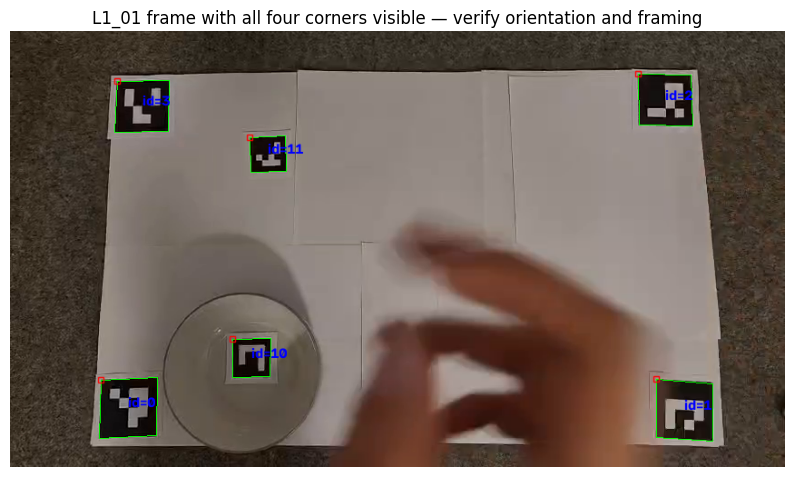

In [ ]:
# Find a frame with all four corner markers visible (the first frame may be occluded).
sample_video = RAW_DIR / by_stem['L1_01'][0].name
cap = cv2.VideoCapture(str(sample_video))
assert cap.isOpened(), f'Could not open {sample_video}'

sample_frame = None
sample_centres = None
fps_sample = cap.get(cv2.CAP_PROP_FPS) or 30.0
max_scan = min(int(fps_sample * 3), 90)

for _ in range(max_scan):
    ok, candidate = cap.read()
    if not ok:
        break
    gray_candidate = cv2.cvtColor(candidate, cv2.COLOR_BGR2GRAY)
    corners_candidate, ids_candidate, _ = detector.detectMarkers(gray_candidate)
    ids_set = set() if ids_candidate is None else set(ids_candidate.flatten().tolist())
    if {0, 1, 2, 3}.issubset(ids_set):
        sample_frame = candidate
        sample_centres = {
            int(marker_id): corner.reshape(4, 2).mean(axis=0)
            for corner, marker_id in zip(corners_candidate, ids_candidate.flatten())
        }
        break
cap.release()

if sample_frame is None:
    raise RuntimeError(
        'Could not find a frame with all four corner markers in the first 3 seconds. '
        'Inspect the video or increase max_scan.'
    )

# Redetect on the selected frame for drawing the marker IDs.
gray = cv2.cvtColor(sample_frame, cv2.COLOR_BGR2GRAY)
corners, ids, _ = detector.detectMarkers(gray)
cv2.aruco.drawDetectedMarkers(sample_frame, corners, ids)

for marker_id in sorted(sample_centres):
    x, y = sample_centres[marker_id]
    print(f'ID {marker_id}: pixel centre=({x:.1f}, {y:.1f})')

expected_corner_position = {
    0: 'bottom-left', 1: 'bottom-right',
    2: 'top-right', 3: 'top-left'
}
frame_h, frame_w = sample_frame.shape[:2]
print('\nCorner marker quadrant check (rough check; manually inspect image too):')
for marker_id, expected_position in expected_corner_position.items():
    x, y = sample_centres[marker_id]
    horizontal = 'left' if x < frame_w / 2 else 'right'
    vertical = 'top' if y < frame_h / 2 else 'bottom'
    actual_position = f'{vertical}-{horizontal}'
    print(f'ID {marker_id}: expected {expected_position}, appears {actual_position}')

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(sample_frame, cv2.COLOR_BGR2RGB))
plt.title('L1_01 frame with all four corners visible — verify orientation and framing')
plt.axis('off')
plt.show()

## 4. Extract all trajectories and run quality checks

This produces `.npz` trajectory arrays, `.json` quality reports, `_qc.png` plots, and a master CSV. An endpoint warning does not automatically mean the physical demonstration failed; it flags a discrepancy between the estimated object-marker endpoint and target-marker centre.

In [ ]:
TRACKS_DIR.mkdir(parents=True, exist_ok=True)

CORNER_IDS = {0, 1, 2, 3}
TRACKED_IDS = {0, 1, 2, 3, 10, 11}
results = []

files_by_stem = {p.stem: p for p in RAW_DIR.iterdir()
                 if p.is_file() and p.suffix.lower() in VIDEO_EXTENSIONS}

for index, stem in enumerate(EXPECTED_NAMES, start=1):
    video = files_by_stem.get(stem)
    if video is None:
        results.append({'video': stem, 'status': 'MISSING_INPUT'})
        continue

    print(f'[{index}/20] {video.name}')
    cap = cv2.VideoCapture(str(video))
    if not cap.isOpened():
        results.append({'video': video.name, 'status': 'VIDEO_OPEN_FAILED'})
        continue

    frame_count = 0
    marker_counts = {i: 0 for i in TRACKED_IDS}
    all_four_corners_frames = 0

    while True:
        ok, frame = cap.read()
        if not ok:
            break
        frame_count += 1
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        corners, ids, _ = detector.detectMarkers(gray)
        visible = set() if ids is None else set(ids.flatten().tolist())
        for marker_id in TRACKED_IDS:
            marker_counts[marker_id] += int(marker_id in visible)
        if CORNER_IDS.issubset(visible):
            all_four_corners_frames += 1
    cap.release()

    if frame_count == 0:
        results.append({'video': video.name, 'status': 'NO_READABLE_FRAMES'})
        continue

    out_npz = TRACKS_DIR / f'{stem}.npz'
    out_json = TRACKS_DIR / f'{stem}.json'
    out_png = TRACKS_DIR / f'{stem}_qc.png'
    for old in (out_npz, out_json, out_png):
        old.unlink(missing_ok=True)

    command = [
        sys.executable, str(SCRIPT_PATH), str(video),
        '--out', str(out_npz), '--layout', stem.split('_')[0],
        '--table-w', str(TABLE_W_M), '--table-h', str(TABLE_H_M),
        '--cam-height', str(CAM_HEIGHT_M),
    ]
    run = subprocess.run(command, capture_output=True, text=True)

    qc = None
    if run.returncode == 0 and out_json.exists():
        try:
            qc = json.loads(out_json.read_text())
        except json.JSONDecodeError:
            pass

    if run.returncode != 0 or qc is None:
        status = 'EXTRACTION_FAILED'
        error_text = (run.stderr or run.stdout)[-1500:]
    elif not qc.get('ok', False):
        status = 'QC_WARNING'
        error_text = '; '.join(qc.get('warnings', []))
    elif all_four_corners_frames < 10:
        status = 'REVIEW_CORNER_VISIBILITY'
        error_text = 'Fewer than 10 frames with all four corner markers'
    else:
        status = 'PASS'
        error_text = ''

    results.append({
        'video': video.name,
        'frames': frame_count,
        'corner_0_frames': marker_counts[0],
        'corner_1_frames': marker_counts[1],
        'corner_2_frames': marker_counts[2],
        'corner_3_frames': marker_counts[3],
        'frames_all_4_corners': all_four_corners_frames,
        'object_detection_rate': round(marker_counts[10] / frame_count, 3),
        'target_detection_rate': round(marker_counts[11] / frame_count, 3),
        'transit_s': qc.get('transit_s') if qc else None,
        'lift_cm': round(qc['max_lift_m'] * 100, 2) if qc and qc.get('max_lift_m') is not None else None,
        'start_to_end_cm': round(qc['start_to_end_m'] * 100, 2) if qc and qc.get('start_to_end_m') is not None else None,
        'target_error_cm': round(qc['end_to_plate_marker_m'] * 100, 2) if qc and qc.get('end_to_plate_marker_m') is not None else None,
        'warnings': error_text,
        'qc_ok': qc.get('ok') if qc else False,
        'status': status,
    })
    print('  status:', status, '| all-four-corner frames:', all_four_corners_frames)
    if error_text:
        print('  detail:', error_text[:500])

quality_df = pd.DataFrame(results)
quality_csv = TRACKS_DIR / 'quality_sweep.csv'
quality_df.to_csv(quality_csv, index=False)

print('\nQuality status counts:')
print(quality_df['status'].value_counts(dropna=False).to_string())
print('\nQuality table:')
display(quality_df[[c for c in [
    'video', 'frames_all_4_corners', 'object_detection_rate',
    'target_detection_rate', 'lift_cm', 'target_error_cm', 'status'
] if c in quality_df.columns]])
print('\nReports and trajectory files:', TRACKS_DIR)

[1/20] L1_01.mp4
  status: QC_WARNING | all-four-corner frames: 115
  detail: object ended >6 cm from plate marker: check marker placement / that it was placed on the plate
[2/20] L1_02.mp4
  status: PASS | all-four-corner frames: 23
[3/20] L1_03.mp4
  status: PASS | all-four-corner frames: 144
[4/20] L1_04.mp4
  status: QC_WARNING | all-four-corner frames: 100
  detail: object ended >6 cm from plate marker: check marker placement / that it was placed on the plate
[5/20] L2_01.mp4
  status: PASS | all-four-corner frames: 162
[6/20] L2_02.mp4
  status: PASS | all-four-corner frames: 58
[7/20] L2_03.mp4
  status: PASS | all-four-corner frames: 133
[8/20] L2_04.mp4
  status: PASS | all-four-corner frames: 194
[9/20] L3_01.mp4
  status: PASS | all-four-corner frames: 197
[10/20] L3_02.mp4
  status: PASS | all-four-corner frames: 118
[11/20] L3_03.mp4
  status: PASS | all-four-corner frames: 124
[12/20] L3_04.mp4
  status: PASS | all-four-corner frames: 144
[13/20] L4_01.mp4
  status: QC_WA

,video,frames_all_4_corners,object_detection_rate,target_detection_rate,lift_cm,target_error_cm,status
0,L1_01.mp4,115,1.000,0.629,9.21,9.80,QC_WARNING
1,L1_02.mp4,23,1.000,0.630,6.26,5.71,PASS
2,L1_03.mp4,144,0.988,0.582,8.21,5.06,PASS
3,L1_04.mp4,100,1.000,0.578,4.94,7.36,QC_WARNING
4,L2_01.mp4,162,0.951,0.564,9.19,3.67,PASS
5,L2_02.mp4,58,0.988,0.523,12.13,3.52,PASS
6,L2_03.mp4,133,0.910,0.500,10.01,4.35,PASS
7,L2_04.mp4,194,1.000,0.588,14.89,2.08,PASS
8,L3_01.mp4,197,0.965,0.545,4.98,5.71,PASS
9,L3_02.mp4,118,0.966,0.483,3.76,3.12,PASS



Reports and trajectory files: /content/tracks_quality_sweep


## 5. Inspect warnings (optional but recommended)

This displays the QC plots for videos whose endpoint distance exceeded the extractor's 6 cm threshold. It does not automatically reject those recordings.

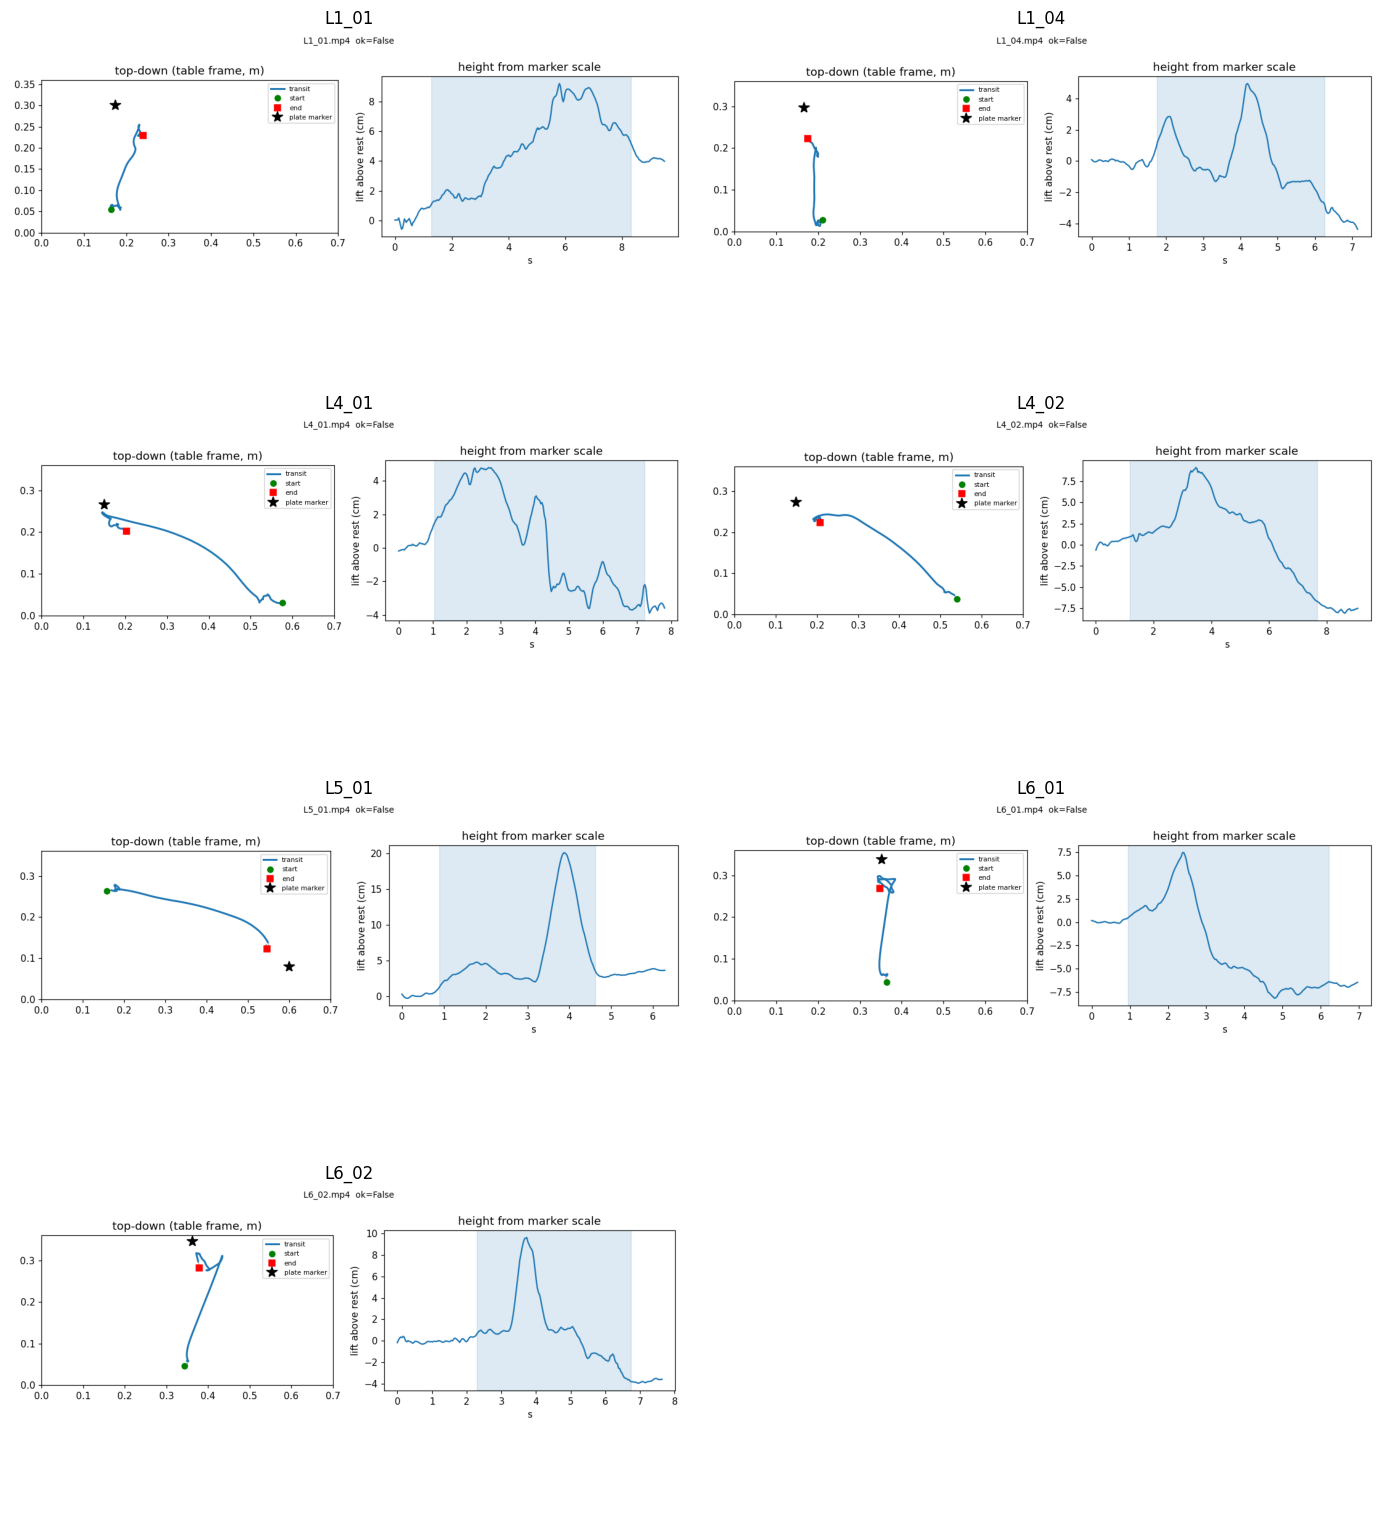

In [ ]:
warning_names = []
if 'quality_df' in globals() and not quality_df.empty:
    warning_names = [Path(v).stem for v in quality_df.loc[
        quality_df['status'] == 'QC_WARNING', 'video'
    ].astype(str)]

if not warning_names:
    print('No QC_WARNING plots to display.')
else:
    ncols = 2
    nrows = int(np.ceil(len(warning_names) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, name in zip(axes, warning_names):
        plot_path = TRACKS_DIR / f'{name}_qc.png'
        if plot_path.exists():
            ax.imshow(plt.imread(plot_path))
            ax.set_title(name)
        else:
            ax.text(0.5, 0.5, f'Missing plot: {name}', ha='center', va='center')
        ax.axis('off')
    for ax in axes[len(warning_names):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

## 6. Normalise all 20 2D transit trajectories

Each path is resampled to 50 points and expressed in an individual start-to-end frame:
- `along`: forward progress relative to that demonstration's endpoint distance;
- `lateral`: side-to-side deviation relative to its direction of travel.

This makes path **shape** comparable across different directions and distances. It does not fix calibration errors, and the extracted Z/height channel is intentionally excluded from this path-learning step.

Training trajectories: 16 / 16
Held-out trajectories: 4 / 4


,video,split,endpoint_distance_cm,path_length_cm,original_qc_ok,target_error_cm,qc_warnings
0,L1_01,train,17.74,30.49,False,9.80,object ended >6 cm from plate marker: check ma...
1,L1_02,train,25.76,36.47,True,5.71,
2,L1_03,train,25.36,39.74,True,5.06,
3,L1_04,train,18.88,30.57,False,7.36,object ended >6 cm from plate marker: check ma...
4,L2_01,train,33.11,39.85,True,3.67,
5,L2_02,train,36.13,57.52,True,3.52,
6,L2_03,train,32.91,46.54,True,4.35,
7,L2_04,train,36.74,49.19,True,2.08,
8,L3_01,train,30.81,47.15,True,5.71,
9,L3_02,train,32.07,36.93,True,3.12,


Saved: /content/normalized_dataset/normalized_xy_paths.npz


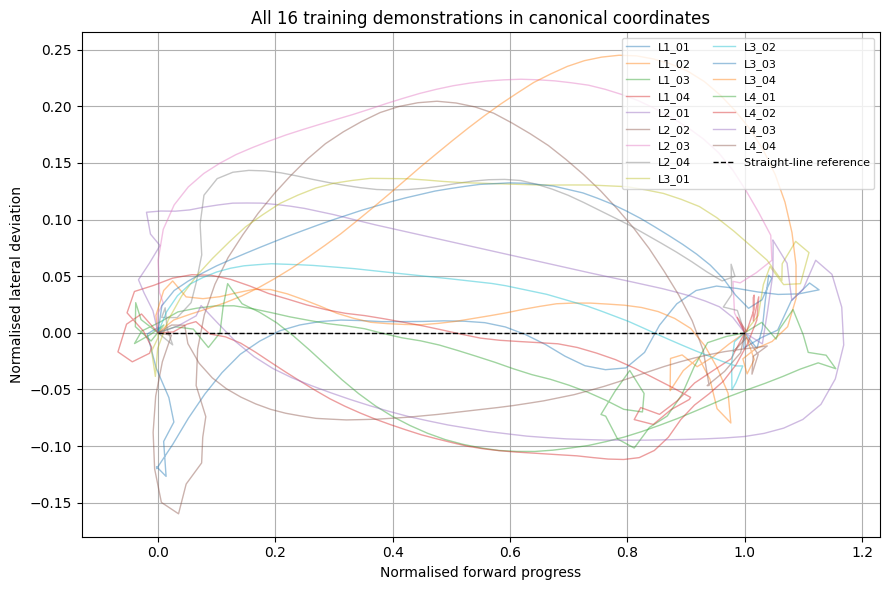

In [ ]:
NORMALIZED_DIR.mkdir(parents=True, exist_ok=True)
N_POINTS = 50

def normalise_trajectory(npz_path, n_points=50):
    data = np.load(npz_path)
    xyz = np.asarray(data['xyz'], dtype=float)
    grasp_idx = int(np.asarray(data['grasp_idx']).item())
    release_idx = int(np.asarray(data['release_idx']).item())

    if not (0 <= grasp_idx < release_idx < len(xyz)):
        raise ValueError('Invalid grasp/release indices')

    path = xyz[grasp_idx:release_idx + 1, :2]
    path = path[np.isfinite(path).all(axis=1)]
    if len(path) < 5:
        raise ValueError('Too few valid trajectory points')

    step_lengths = np.linalg.norm(np.diff(path, axis=0), axis=1)
    arc = np.concatenate([[0.0], np.cumsum(step_lengths)])
    keep = np.concatenate([[True], np.diff(arc) > 1e-8])
    path, arc = path[keep], arc[keep]
    if len(path) < 5 or arc[-1] < 1e-4:
        raise ValueError('Trajectory has insufficient movement')

    query_arc = np.linspace(0.0, arc[-1], n_points)
    sampled = np.column_stack([
        np.interp(query_arc, arc, path[:, axis]) for axis in range(2)
    ])

    displacement = sampled[-1] - sampled[0]
    endpoint_distance = np.linalg.norm(displacement)
    if endpoint_distance < 1e-3:
        raise ValueError('Start and endpoint are too close')

    forward = displacement / endpoint_distance
    lateral_axis = np.array([-forward[1], forward[0]])
    relative = sampled - sampled[0]
    along = (relative @ forward) / endpoint_distance
    sideways = (relative @ lateral_axis) / endpoint_distance
    canonical = np.column_stack([along, sideways])
    path_length = arc[-1]
    return canonical, endpoint_distance, path_length

paths = {}
metadata_rows = []
missing_tracks = []

for name in EXPECTED_NAMES:
    npz_path = TRACKS_DIR / f'{name}.npz'
    json_path = TRACKS_DIR / f'{name}.json'
    if not npz_path.exists():
        missing_tracks.append(name)
        continue

    try:
        canonical, endpoint_distance, path_length = normalise_trajectory(npz_path, N_POINTS)
        paths[name] = canonical
        qc = json.loads(json_path.read_text()) if json_path.exists() else {}
        metadata_rows.append({
            'video': name,
            'split': 'train' if name in TRAIN_NAMES else 'test',
            'endpoint_distance_cm': round(endpoint_distance * 100, 2),
            'path_length_cm': round(path_length * 100, 2),
            'original_qc_ok': qc.get('ok'),
            'target_error_cm': round(qc['end_to_plate_marker_m'] * 100, 2)
                if qc.get('end_to_plate_marker_m') is not None else None,
            'qc_warnings': '; '.join(qc.get('warnings', [])),
        })
    except Exception as exc:
        print(f'Could not normalise {name}: {exc}')
        missing_tracks.append(name)

train_available = [name for name in TRAIN_NAMES if name in paths]
test_available = [name for name in TEST_NAMES if name in paths]

print('Training trajectories:', len(train_available), '/ 16')
print('Held-out trajectories:', len(test_available), '/ 4')
if missing_tracks:
    print('Missing/unusable tracks:', missing_tracks)
    raise RuntimeError('Not all 20 trajectories are available. Review extraction failures before modelling.')

train_paths = np.stack([paths[name] for name in TRAIN_NAMES])
test_paths = np.stack([paths[name] for name in TEST_NAMES])

np.savez_compressed(
    NORMALIZED_DIR / 'normalized_xy_paths.npz',
    train_paths=train_paths,
    train_names=np.array(TRAIN_NAMES),
    test_paths=test_paths,
    test_names=np.array(TEST_NAMES),
)
metadata_df = pd.DataFrame(metadata_rows)
metadata_df.to_csv(NORMALIZED_DIR / 'trajectory_metadata.csv', index=False)

display(metadata_df)
print('Saved:', NORMALIZED_DIR / 'normalized_xy_paths.npz')

plt.figure(figsize=(9, 6))
for name, path in zip(TRAIN_NAMES, train_paths):
    plt.plot(path[:, 0], path[:, 1], alpha=0.45, linewidth=1, label=name)
plt.plot([0, 1], [0, 0], '--', color='black', linewidth=1, label='Straight-line reference')
plt.xlabel('Normalised forward progress')
plt.ylabel('Normalised lateral deviation')
plt.title('All 16 training demonstrations in canonical coordinates')
plt.grid(True)
plt.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

## 7. Fit the global median motion prior and report variation

The prior is computed from the 16 training demonstrations only. L5 and L6 remain held out and are not used to fit or tune the prior.

HAND2PANDA — MOTION PRIOR REPORT
Training demonstrations: 16
Held-out demonstrations: 4
Points per trajectory: 50
Training data contains NaN: False
Training data contains Inf: False
Median path start: [0. 0.]
Median path middle: [0.5837 0.0334]
Median path end: [ 1. -0.]
Maximum absolute lateral deviation of median: 0.045
Median lateral standard deviation: 0.0788
Maximum lateral standard deviation: 0.1132
Median 10th–90th percentile width: 0.197
Maximum 10th–90th percentile width: 0.3105
Saved motion prior: /content/normalized_dataset/motion_prior.npz


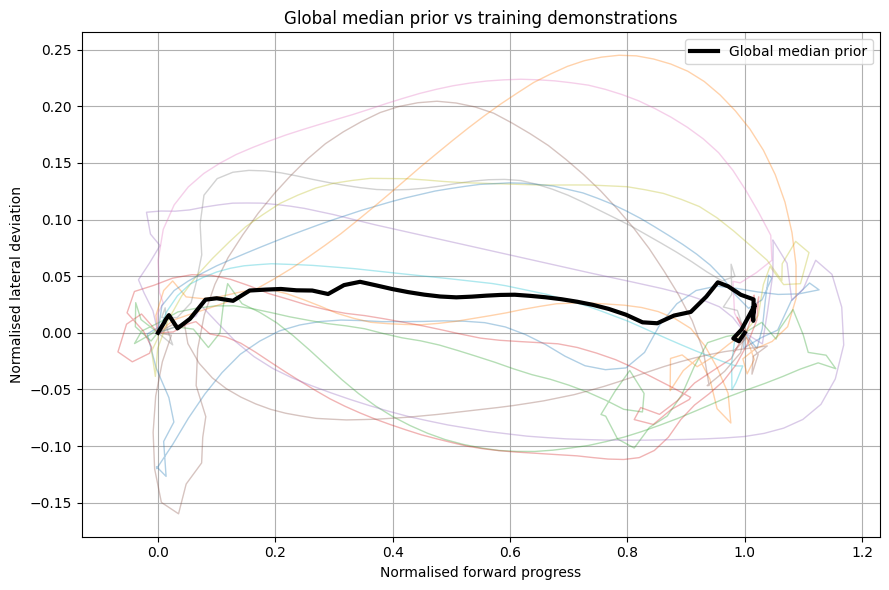

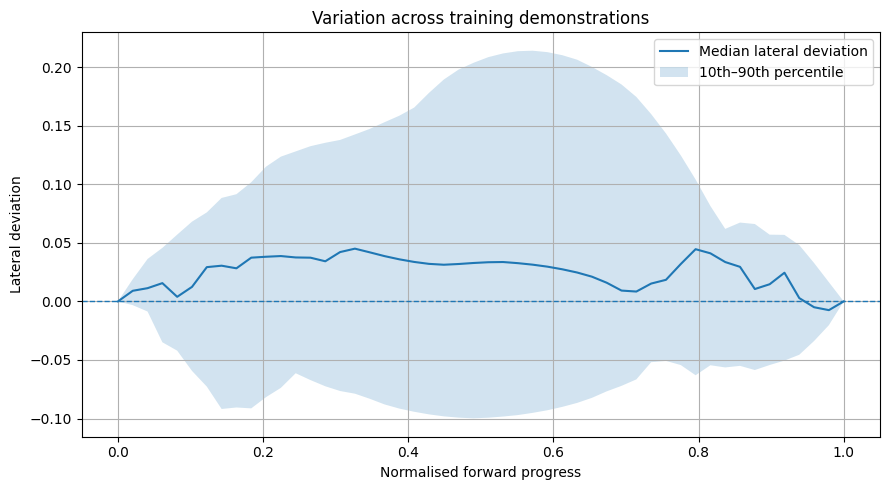


Layout-median consistency (mean distance from global median):
L1: within-batch mean deviation=0.0575; layout-vs-global=0.0890
L2: within-batch mean deviation=0.0657; layout-vs-global=0.1231
L3: within-batch mean deviation=0.0534; layout-vs-global=0.0664
L4: within-batch mean deviation=0.0482; layout-vs-global=0.0964


In [ ]:
train_paths = np.asarray(train_paths)
median_path = np.median(train_paths, axis=0)
q10 = np.percentile(train_paths, 10, axis=0)
q90 = np.percentile(train_paths, 90, axis=0)
std_path = np.std(train_paths, axis=0)

prior_path = NORMALIZED_DIR / 'motion_prior.npz'
np.savez_compressed(
    prior_path,
    median_path=median_path,
    q10=q10,
    q90=q90,
    std_path=std_path,
    train_names=np.array(TRAIN_NAMES),
)

lateral_width = q90[:, 1] - q10[:, 1]
print('HAND2PANDA — MOTION PRIOR REPORT')
print('Training demonstrations:', len(train_paths))
print('Held-out demonstrations:', len(test_paths))
print('Points per trajectory:', train_paths.shape[1])
print('Training data contains NaN:', np.isnan(train_paths).any())
print('Training data contains Inf:', np.isinf(train_paths).any())
print('Median path start:', np.round(median_path[0], 4))
print('Median path middle:', np.round(median_path[len(median_path)//2], 4))
print('Median path end:', np.round(median_path[-1], 4))
print('Maximum absolute lateral deviation of median:', round(np.max(np.abs(median_path[:, 1])), 4))
print('Median lateral standard deviation:', round(np.median(std_path[:, 1]), 4))
print('Maximum lateral standard deviation:', round(np.max(std_path[:, 1]), 4))
print('Median 10th–90th percentile width:', round(np.median(lateral_width), 4))
print('Maximum 10th–90th percentile width:', round(np.max(lateral_width), 4))
print('Saved motion prior:', prior_path)

plt.figure(figsize=(9, 6))
for name, path in zip(TRAIN_NAMES, train_paths):
    plt.plot(path[:, 0], path[:, 1], alpha=0.35, linewidth=1)
plt.plot(median_path[:, 0], median_path[:, 1], color='black', linewidth=3, label='Global median prior')
plt.xlabel('Normalised forward progress')
plt.ylabel('Normalised lateral deviation')
plt.title('Global median prior vs training demonstrations')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

progress = np.linspace(0, 1, len(median_path))
plt.figure(figsize=(9, 5))
plt.plot(progress, median_path[:, 1], label='Median lateral deviation')
plt.fill_between(progress, q10[:, 1], q90[:, 1], alpha=0.2, label='10th–90th percentile')
plt.axhline(0, linestyle='--', linewidth=1)
plt.xlabel('Normalised forward progress')
plt.ylabel('Lateral deviation')
plt.title('Variation across training demonstrations')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Layout medians are diagnostic only; they do not use held-out L5/L6.
global_median = median_path
print('\nLayout-median consistency (mean distance from global median):')
for layout in ['L1', 'L2', 'L3', 'L4']:
    indices = [i for i, name in enumerate(TRAIN_NAMES) if name.startswith(layout + '_')]
    batch_median = np.median(train_paths[indices], axis=0)
    distance = np.mean(np.linalg.norm(batch_median - global_median, axis=1))
    within = np.mean(np.linalg.norm(train_paths[indices] - batch_median, axis=2))
    print(f'{layout}: within-batch mean deviation={within:.4f}; layout-vs-global={distance:.4f}')

## 8. Back up all outputs to Google Drive

This backs up the extracted trajectories, QC reports/plots, normalised dataset, metadata, motion prior and the extractor script. Run after the preceding cells succeed.

In [ ]:
DRIVE_OUT = Path('/content/drive/MyDrive/Humanoid/clean_pipeline_outputs')
DRIVE_OUT.mkdir(parents=True, exist_ok=True)

# Copy extractor and QC results.
if SCRIPT_PATH.exists():
    shutil.copy2(SCRIPT_PATH, DRIVE_OUT / SCRIPT_PATH.name)

for source_dir in [TRACKS_DIR, NORMALIZED_DIR]:
    destination = DRIVE_OUT / source_dir.name
    destination.mkdir(parents=True, exist_ok=True)
    for file_path in source_dir.iterdir():
        if file_path.is_file():
            shutil.copy2(file_path, destination / file_path.name)

print('Backed up outputs to:', DRIVE_OUT)
print('QC CSV:', DRIVE_OUT / TRACKS_DIR.name / 'quality_sweep.csv')
print('Normalised paths:', DRIVE_OUT / NORMALIZED_DIR.name / 'normalized_xy_paths.npz')
print('Motion prior:', DRIVE_OUT / NORMALIZED_DIR.name / 'motion_prior.npz')

Backed up outputs to: /content/drive/MyDrive/Humanoid/clean_pipeline_outputs
QC CSV: /content/drive/MyDrive/Humanoid/clean_pipeline_outputs/tracks_quality_sweep/quality_sweep.csv
Normalised paths: /content/drive/MyDrive/Humanoid/clean_pipeline_outputs/normalized_dataset/normalized_xy_paths.npz
Motion prior: /content/drive/MyDrive/Humanoid/clean_pipeline_outputs/normalized_dataset/motion_prior.npz


## Next milestone — not implemented in this notebook yet

1. Load the existing LIBERO task and Panda controller from the SmolVLA smoke-test notebook.
2. Use simulator state to get the bowl/object start and goal positions.
3. Transform `motion_prior.npz` from normalised `(along, lateral)` coordinates into the simulator's XY plane.
4. Execute one demonstration-derived path with geometric approach, grasp, safe lift, lower and release phases. Do **not** use the uncertain estimated video heights as robot Z commands.
5. Run the same task with a straight-line baseline under equivalent conditions.
6. Record success, endpoint error and path quality. Keep L5/L6 as held-out data and report the calibration limitations honestly.

The current notebook stops at the learned 2D motion prior. It does not yet claim to train SmolVLA on the phone videos or to control the Panda with them.